# Late Delivery Risk Prediction – DataCo Supply Chain
**Problem statement:** How can we analyse and predict whether an order is at risk of late delivery based on shipping mode, geography and product category?

**Notebook flow**
| Step | Content |
|---|---|
| 1–3 | Setup, load & merge tables, data overview |
| 4–8 | Descriptive analysis – Research Objectives 1 to 5 |
| 9–10 | Predictive modelling and prediction export |
| 11–12 | Power BI tables and download of all outputs |

Run the cells top to bottom (Runtime → Run all).

---
## Step 1 – Setup
Imports the libraries, points to the public GitHub repo holding the CSV files, and defines three helpers:
- `rd()` reads a CSV from GitHub and trims stray spaces
- `save()` saves a chart as PNG
- `chi()` runs a chi-square test (is the difference in late % statistically real?) and reports Cramér's V (effect size: 0 = none, 1 = perfect association)

In [ ]:
# 1. Setup
import os, warnings, shutil
from urllib.parse import quote
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px
from scipy.stats import chi2_contingency
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})

DATA_DIR = 'https://raw.githubusercontent.com/edwinthl71/Capstone-SSC/main/'   # public GitHub repo
OUT_DIR = '/content/outputs/'            # charts + model outputs (temporary Colab storage; zipped & downloaded at the end)
os.makedirs(OUT_DIR, exist_ok=True)

def rd(f):
    url = DATA_DIR + quote(f)            # quote() handles spaces in file names
    try:    df = pd.read_csv(url, encoding='utf-8')
    except UnicodeDecodeError: df = pd.read_csv(url, encoding='latin-1')
    for c in df.select_dtypes('object'):
        df[c] = df[c].str.strip().str.replace(r'\s+', ' ', regex=True)
    return df

def save(name):
    plt.tight_layout(); plt.savefig(OUT_DIR + name + '.png', dpi=200, bbox_inches='tight'); plt.show()

def chi(col, data=None):
    d = orders if data is None else data
    ct = pd.crosstab(d[col], d['late']); c, p, _, _ = chi2_contingency(ct)
    v = np.sqrt(c / (ct.values.sum() * (min(ct.shape) - 1)))
    print(f'Chi-square test ({col}): p = {p:.3g}, Cramér\'s V = {v:.3f}')

## Step 2 – Load, merge and prepare the data
**What this does**
- Joins the tables into one **order-level** table (`orders`): Orders + Shipping + Geography + Payment Types + Customers.
- Drops customer personal data (name, email, password, street) – not needed and best kept out of a public repo.
- Parses the mixed date formats and creates `delay_days` = actual − scheduled shipping days, plus year / quarter / month / weekday / hour.
- Builds an **item-level** table (`items`): Order Items + Products + Categories + Departments. Each item inherits its order's late flag (used for the category analysis).
- Creates order-level features from the items (number of items, quantity, order value, discount, primary category / department).
- Creates a customer **value tier** (Low / Medium / High, by total spend) for Objective 4.
- Saves the cleaned `master_orders.csv`.

**Checks printed:** table sizes, date range, missing values, overall late rate, and how closely `late` matches "actual > scheduled days".

In [ ]:
# 2. Load & merge tables
cust = rd('Customers.csv').drop(columns=['Customer Fname', 'Customer Lname', 'Customer Email',
                                        'Customer Password', 'Customer Street'])  # drop PII
geo, ship, pay = rd('Geography.csv'), rd('Shipping.csv'), rd('Payment Types.csv')
prod, cat, dept = rd('Products.csv'), rd('Categories.csv'), rd('Departments.csv')

orders = (rd('Orders.csv')
          .merge(ship, on='Shipment_Id', how='left')
          .merge(geo, on='Location_Id', how='left')
          .merge(pay, on='Payment_Type_ID', how='left')
          .merge(cust[['Customer Id', 'Customer Segment']], left_on='Order Customer Id',
                 right_on='Customer Id', how='left'))
orders = orders.rename(columns={
    'Late_delivery_risk': 'late', 'Days for shipping (real)': 'days_real',
    'Days for shipment (scheduled)': 'days_sched', 'order date (DateOrders)': 'order_date',
    'shipping date (DateOrders)': 'ship_date', 'Shipping Mode': 'ship_mode', 'Market': 'market',
    'Order Region': 'region', 'Order Country': 'country', 'Order City': 'city',
    'Customer Segment': 'segment', 'Type': 'payment_type'})

# dates (mixed formats in source)
orders['order_date'] = pd.to_datetime(orders['order_date'], format='mixed')
orders['ship_date'] = pd.to_datetime(orders['ship_date'], format='mixed')
orders['delay_days'] = orders['days_real'] - orders['days_sched']      # >0 = shipped later than scheduled
orders['year'] = orders.order_date.dt.year
orders['month'] = orders.order_date.dt.month
orders['quarter'] = orders.order_date.dt.to_period('Q').astype(str)
orders['dow'] = orders.order_date.dt.dayofweek
orders['hour'] = orders.order_date.dt.hour

# line items -> products -> categories -> departments
items = (rd('Order Items.csv')
         .merge(prod[['Product Card Id', 'Product Category Id']], on='Product Card Id', how='left')
         .merge(cat, left_on='Product Category Id', right_on='Category Id', how='left')
         .merge(dept, on='Department Id', how='left')
         .rename(columns={'Department Name': 'department'}))
dup = items.groupby('Category Name')['Category Id'].transform('nunique') > 1   # e.g. "Electronics" in 2 depts
items['category'] = np.where(dup, items['Category Name'] + ' (' + items['department'] + ')', items['Category Name'])

# order-level item features
agg = items.groupby('Order Id').agg(n_items=('Order Item Id', 'count'), total_qty=('Order Item Quantity', 'sum'),
                                    order_sales=('Order Item Total', 'sum'),
                                    avg_discount_rate=('Order Item Discount Rate', 'mean'),
                                    avg_unit_price=('Order Item Product Price', 'mean')).reset_index()
prim = (items.sort_values('Sales', ascending=False).drop_duplicates('Order Id')
        [['Order Id', 'category', 'department']]
        .rename(columns={'category': 'primary_category', 'department': 'primary_dept'}))
orders = orders.merge(agg, on='Order Id', how='left').merge(prim, on='Order Id', how='left')

# customer value tier (by total spend) for Objective 4
spend = orders.groupby('Order Customer Id')['order_sales'].sum()
tier = pd.qcut(spend.rank(method='first'), 3, labels=['Low value', 'Medium value', 'High value'])
orders['value_tier'] = orders['Order Customer Id'].map(tier)

# item-level table carrying the order's late flag (Objective 3)
items = items.merge(orders[['Order Id', 'late']], on='Order Id', how='left')

orders.to_csv(OUT_DIR + 'master_orders.csv', index=False)
print('Orders:', orders.shape, '| Items:', items.shape)
print('Date range:', orders.order_date.min().date(), '→', orders.order_date.max().date())
print('Missing values (top):\n', orders.isna().sum().sort_values(ascending=False).head(5))
print('late == (real > scheduled)?', (orders.late == (orders.days_real > orders.days_sched)).mean().round(4))
print(f'Overall late rate: {orders.late.mean():.1%}')

Orders: (65752, 38) | Items: (180519, 22)
Date range: 2015-01-01 → 2018-01-31
Missing values (top):
 Order Zipcode      57482
Order Id               0
Payment_Type_ID        0
Shipment_Id            0
Location_Id            0
dtype: int64
late == (real > scheduled)? 0.9749
Overall late rate: 54.8%


## Step 3 – Data overview
Two quick charts to understand the target before analysing it:
- **Class balance** of `Late_delivery_risk` – confirms the model will not face a heavily imbalanced target.
- **Distribution of delay days** (actual − scheduled) – negative = early, 0 = on schedule, positive = late.

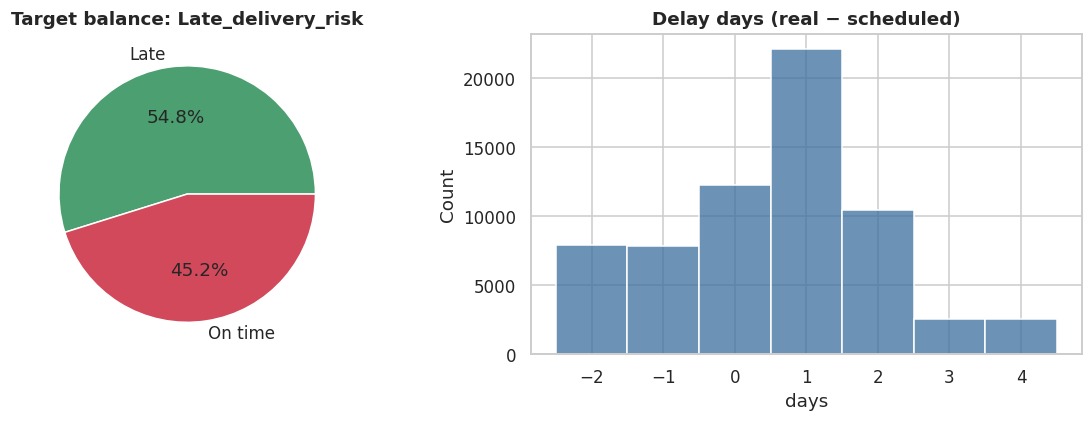

In [ ]:
# 3. Overview
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
orders.late.map({0: 'On time', 1: 'Late'}).value_counts().plot.pie(ax=ax[0], autopct='%1.1f%%',
                                                                   colors=['#4C9F70', '#D1495B'], ylabel='')
ax[0].set_title('Target balance: Late_delivery_risk')
sns.histplot(orders.delay_days, discrete=True, ax=ax[1], color='#3B6E9E')
ax[1].set_title('Delay days (real − scheduled)'); ax[1].set_xlabel('days')
save('00_overview')

## Objective 1 – Shipping Mode Impact Analysis
**Question:** how do shipping modes influence the likelihood of late delivery?

**Visuals:** bar chart of % late by mode, and box plot of delay days per mode.

**How to read it:** the bar chart shows which service level is most prone to delays; the box plot shows *how late* (the spread of delay days). The dashed line is the overall late rate. The table above the charts compares scheduled vs actual days per mode.

**Significance:** a very small chi-square p-value (< 0.05) means the mode genuinely affects lateness; Cramér's V tells you how strong that effect is.

                orders  late_pct  avg_scheduled  avg_real  avg_delay
ship_mode                                                           
Same Day          3571     46.15            0.0      0.48       0.48
First Class      10079     95.27            1.0      2.00       1.00
Second Class     12778     76.72            2.0      4.00       2.00
Standard Class   39324     38.13            4.0      4.00      -0.00
Chi-square test (ship_mode): p = 0, Cramér's V = 0.456


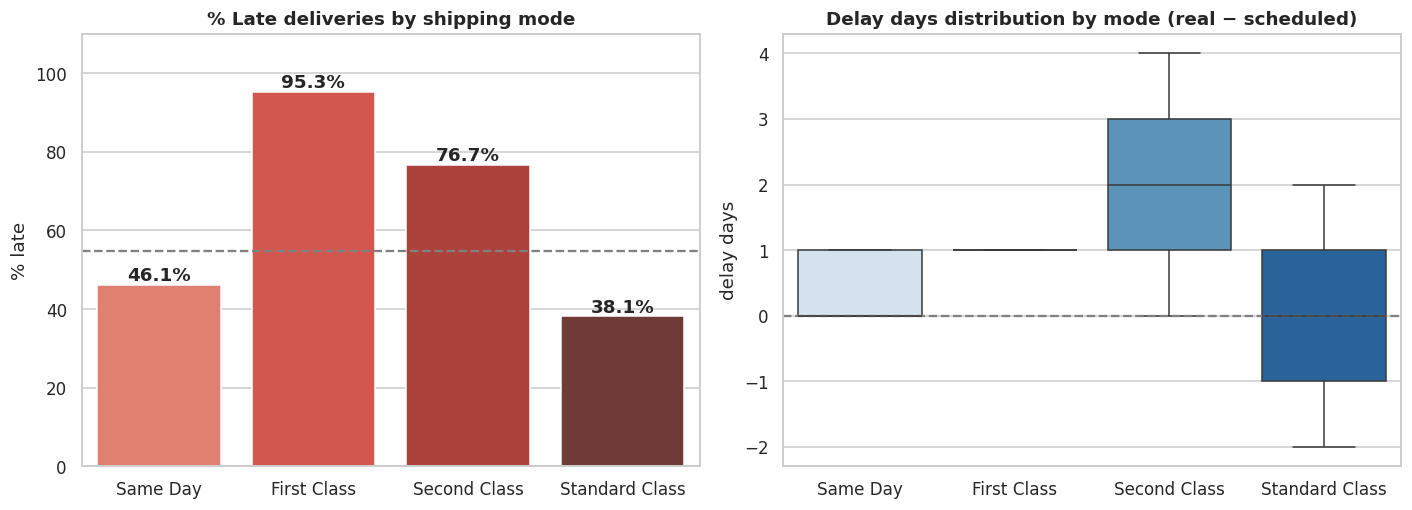

In [ ]:
# 4. OBJECTIVE 1 – Shipping mode impact
mode_order = ['Same Day', 'First Class', 'Second Class', 'Standard Class']
o1 = (orders.groupby('ship_mode').agg(orders=('late', 'size'), late_pct=('late', 'mean'),
      avg_scheduled=('days_sched', 'mean'), avg_real=('days_real', 'mean'), avg_delay=('delay_days', 'mean'))
      .reindex(mode_order))
o1['late_pct'] *= 100
print(o1.round(2)); chi('ship_mode')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sns.barplot(x=o1.index, y=o1.late_pct, ax=ax[0], palette='Reds_d')
for i, v in enumerate(o1.late_pct): ax[0].text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
ax[0].axhline(orders.late.mean() * 100, ls='--', c='grey'); ax[0].set_ylim(0, 110)
ax[0].set_title('% Late deliveries by shipping mode'); ax[0].set_xlabel(''); ax[0].set_ylabel('% late')
sns.boxplot(data=orders, x='ship_mode', y='delay_days', order=mode_order, ax=ax[1], palette='Blues')
ax[1].axhline(0, ls='--', c='grey'); ax[1].set_title('Delay days distribution by mode (real − scheduled)')
ax[1].set_xlabel(''); ax[1].set_ylabel('delay days')
save('01_shipping_mode')

## Objective 2 – Geographic Risk Profiling
**Question:** how does delivery risk vary across regions, countries and cities?

**Visuals:** bar chart of average late risk by region, and an interactive world map of late risk by country (hover for order counts).

**Notes**
- Country names in the source data are in Spanish, so they are mapped to ISO-3 codes for the map.
- Rankings of the highest- and lowest-risk countries only include countries with **at least 100 orders**, so small samples do not distort the picture.
- Check the chi-square result: if p ≥ 0.05, regional differences may just be noise and should be reported as such.

                 orders  late_pct
region                           
Canada              309      49.5
West Africa        1223      51.2
Caribbean          2806      53.0
Southern Europe    3543      53.5
Northern Europe    3716      53.7
Southern Africa     398      53.8
South America      4979      54.1
North Africa       1064      54.3
West of USA        2667      54.4
Oceania            4362      54.6
Eastern Asia       3318      54.8
Central America    9396      54.9
East of USA        2323      54.9
US Center          1935      55.3
Central Asia        184      55.4
Southeast Asia     4356      55.6
Western Europe    10010      55.8
South Asia         3335      55.9
Eastern Europe     1292      56.0
West Asia          2022      56.0
South of USA       1345      56.0
East Africa         613      56.8
Central Africa      556      57.6
market
Africa          54.1
Europe          54.9
LATAM           54.4
Pacific Asia    55.3
USCA            54.8
Name: late, dtype: float64
Chi-square 

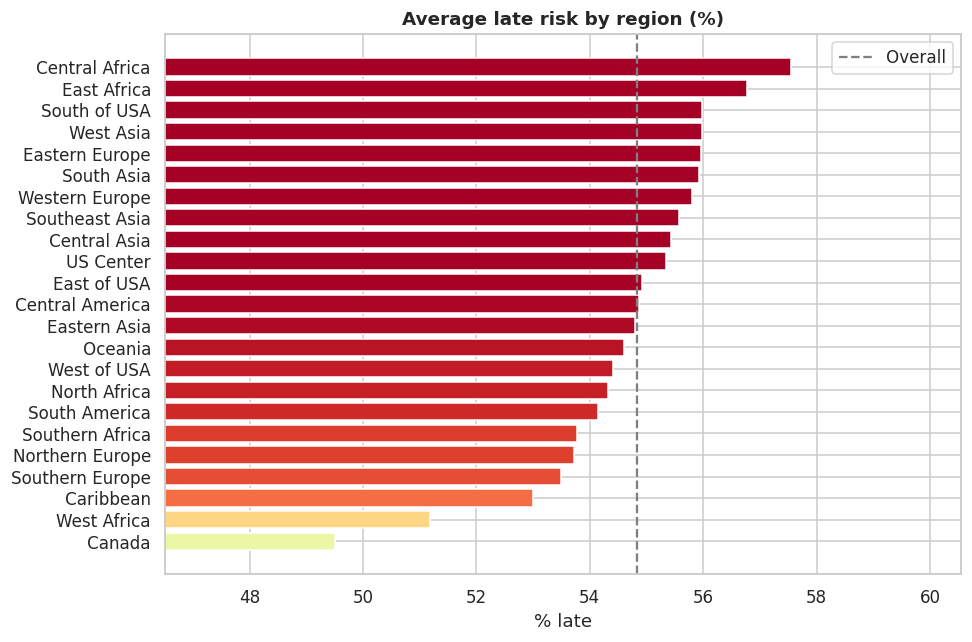

Unmapped countries: []


Highest-risk countries (≥100 orders):
                         country  orders  late_pct
                  Corea del Sur     275      60.7
                        Irlanda     187      60.4
                         Angola     103      60.2
                          Chile     242      59.5
República Democrática del Congo     329      58.7
                        Malasia     255      58.4
                      Venezuela     319      57.7
                          Rusia     322      57.5
Lowest-risk countries (≥100 orders):
   country  orders  late_pct
  Nigeria     765      51.4
     Irak     318      51.3
     Cuba    1191      51.2
   Panamá     656      50.3
   Canada     309      49.5
Finlandia     109      47.7
Dinamarca     110      47.3
 Portugal     120      45.8


In [ ]:
# 5. OBJECTIVE 2 – Geographic risk profiling
orders['region'] = orders['region'].str.strip()
o2_reg = orders.groupby('region').agg(orders=('late', 'size'), late_pct=('late', 'mean')).sort_values('late_pct')
o2_reg['late_pct'] *= 100
print(o2_reg.round(1)); print(orders.groupby('market').late.mean().mul(100).round(1)); chi('region')

plt.figure(figsize=(9, 6))
plt.barh(o2_reg.index, o2_reg.late_pct, color=plt.cm.RdYlGn_r((o2_reg.late_pct - 50) / 10 + .5))
plt.axvline(orders.late.mean() * 100, ls='--', c='grey', label='Overall')
plt.xlim(o2_reg.late_pct.min() - 3, o2_reg.late_pct.max() + 3)
plt.title('Average late risk by region (%)'); plt.xlabel('% late'); plt.legend()
save('02_region_bar')

# Country map (source country names are in Spanish -> ISO-3 codes)
ISO = {'Afganistán':'AFG','Albania':'ALB','Alemania':'DEU','Angola':'AGO','Arabia Saudí':'SAU','Argelia':'DZA','Argentina':'ARG','Armenia':'ARM','Australia':'AUS','Austria':'AUT','Azerbaiyán':'AZE','Bangladés':'BGD','Barbados':'BRB','Baréin':'BHR','Belice':'BLZ','Benín':'BEN','Bielorrusia':'BLR','Bolivia':'BOL','Bosnia y Herzegovina':'BIH','Botsuana':'BWA','Brasil':'BRA','Bulgaria':'BGR','Burkina Faso':'BFA','Burundi':'BDI','Bután':'BTN','Bélgica':'BEL','Camboya':'KHM','Camerún':'CMR','Canada':'CAN','Chad':'TCD','Chile':'CHL','China':'CHN','Chipre':'CYP','Colombia':'COL','Corea del Sur':'KOR','Costa Rica':'CRI','Costa de Marfil':'CIV','Croacia':'HRV','Cuba':'CUB','Dinamarca':'DNK','Ecuador':'ECU','Egipto':'EGY','El Salvador':'SLV','Emiratos Árabes Unidos':'ARE','Eritrea':'ERI','Eslovaquia':'SVK','Eslovenia':'SVN','España':'ESP','Estados Unidos':'USA','Estonia':'EST','Etiopía':'ETH','Filipinas':'PHL','Finlandia':'FIN','Francia':'FRA','Gabón':'GAB','Georgia':'GEO','Ghana':'GHA','Grecia':'GRC','Guadalupe':'GLP','Guatemala':'GTM','Guayana Francesa':'GUF','Guinea':'GIN','Guinea Ecuatorial':'GNQ','Guinea-Bissau':'GNB','Guyana':'GUY','Haití':'HTI','Honduras':'HND','Hong Kong':'HKG','Hungría':'HUN','India':'IND','Indonesia':'IDN','Irak':'IRQ','Irlanda':'IRL','Irán':'IRN','Israel':'ISR','Italia':'ITA','Jamaica':'JAM','Japón':'JPN','Jordania':'JOR','Kazajistán':'KAZ','Kenia':'KEN','Kirguistán':'KGZ','Kuwait':'KWT','Laos':'LAO','Lesoto':'LSO','Liberia':'LBR','Libia':'LBY','Lituania':'LTU','Luxemburgo':'LUX','Líbano':'LBN','Macedonia':'MKD','Madagascar':'MDG','Malasia':'MYS','Mali':'MLI','Marruecos':'MAR','Martinica':'MTQ','Mauritania':'MRT','Moldavia':'MDA','Mongolia':'MNG','Montenegro':'MNE','Mozambique':'MOZ','Myanmar (Birmania)':'MMR','México':'MEX','Namibia':'NAM','Nepal':'NPL','Nicaragua':'NIC','Nigeria':'NGA','Noruega':'NOR','Nueva Zelanda':'NZL','Níger':'NER','Omán':'OMN','Pakistán':'PAK','Panamá':'PAN','Papúa Nueva Guinea':'PNG','Paraguay':'PRY','Países Bajos':'NLD','Perú':'PER','Polonia':'POL','Portugal':'PRT','Qatar':'QAT','Reino Unido':'GBR','República Centroafricana':'CAF','República Checa':'CZE','República Democrática del Congo':'COD','República Dominicana':'DOM','República de Gambia':'GMB','República del Congo':'COG','Ruanda':'RWA','Rumania':'ROU','Rusia':'RUS','Senegal':'SEN','Serbia':'SRB','Sierra Leona':'SLE','Singapur':'SGP','Siria':'SYR','Somalia':'SOM','Sri Lanka':'LKA','Suazilandia':'SWZ','SudAfrica':'ZAF','Sudán':'SDN','Sudán del Sur':'SSD','Suecia':'SWE','Suiza':'CHE','Surinam':'SUR','Sáhara Occidental':'ESH','Tailandia':'THA','Taiwán':'TWN','Tanzania':'TZA','Tayikistán':'TJK','Togo':'TGO','Trinidad y Tobago':'TTO','Turkmenistán':'TKM','Turquía':'TUR','Túnez':'TUN','Ucrania':'UKR','Uganda':'UGA','Uruguay':'URY','Uzbekistán':'UZB','Venezuela':'VEN','Vietnam':'VNM','Yemen':'YEM','Yibuti':'DJI','Zambia':'ZMB','Zimbabue':'ZWE'}
orders['iso3'] = orders['country'].map(ISO)
print('Unmapped countries:', orders.loc[orders.iso3.isna(), 'country'].unique())
o2_cty = orders.groupby(['country', 'iso3']).agg(orders=('late', 'size'), late_pct=('late', 'mean')).reset_index()
o2_cty['late_pct'] = (o2_cty.late_pct * 100).round(1)
fig = px.choropleth(o2_cty, locations='iso3', color='late_pct', hover_name='country', hover_data={'orders': True, 'iso3': False},
                    color_continuous_scale='RdYlGn_r', range_color=(o2_cty.late_pct.quantile(.05), o2_cty.late_pct.quantile(.95)),
                    title='Late delivery risk (%) by destination country')
fig.update_layout(margin=dict(l=0, r=0, t=50, b=0)); fig.show(); fig.write_html(OUT_DIR + '02_country_map.html')

big = o2_cty[o2_cty.orders >= 100].sort_values('late_pct', ascending=False)   # reliable sample sizes only
print('Highest-risk countries (≥100 orders):\n', big.head(8)[['country', 'orders', 'late_pct']].to_string(index=False))
print('Lowest-risk countries (≥100 orders):\n', big.tail(8)[['country', 'orders', 'late_pct']].to_string(index=False))

## Objective 3 – Product Category Sensitivity
**Question:** are certain product categories or departments more likely to be delivered late?

**Visuals:** treemap (box size = number of late items, colour = late %) and a 100% stacked bar of on-time vs late by department.

**Notes**
- Analysis is at **item level**: each item takes the late flag of its order.
- Categories with few items (e.g. a handful of orders) can show extreme percentages – look at the `items` count before drawing conclusions.
- "Electronics" appears under two departments, so those categories are labelled with their department.

                   On time %  Late %
department                          
Discs Shop              45.6    54.4
Footwear                45.3    54.7
Apparel                 45.3    54.7
Fan Shop                45.2    54.8
Golf                    45.2    54.8
Technology              45.0    55.0
Outdoors                44.5    55.5
Fitness                 44.5    55.5
Health and Beauty       44.2    55.8
Book Shop               43.5    56.5
Pet Shop                41.1    58.9
Chi-square test (department): p = 0.756, Cramér's V = 0.006


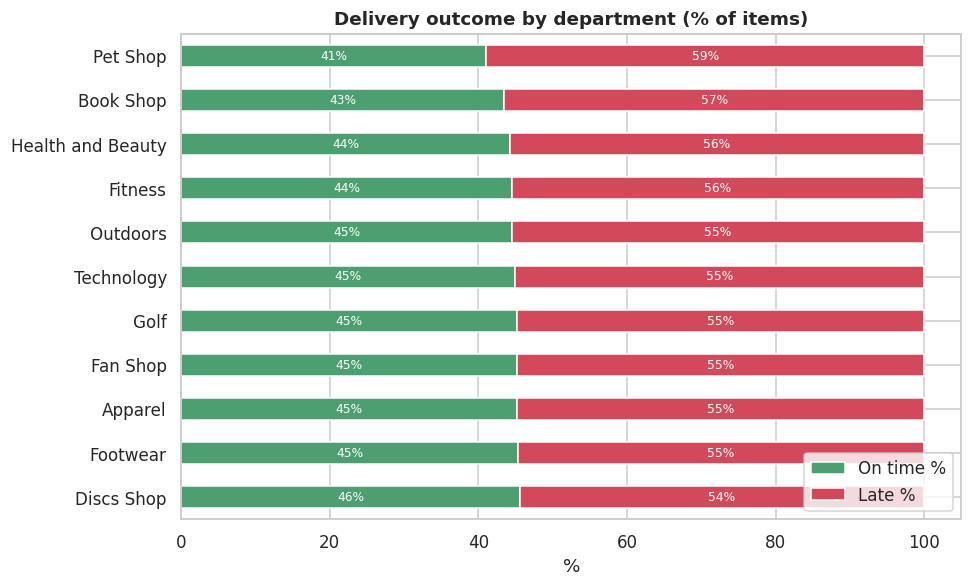

Top 5 / bottom 5 categories by late %:
          category  items  late_pct
 Men's Golf Clubs    283      47.7
        Computers    442      50.7
     Golf Apparel    441      51.9
              CDs    271      52.0
             Baby    207      52.7
Strength Training    111      57.7
          Cameras    592      58.1
     Pet Supplies    492      58.9
         Lacrosse    343      60.1
Golf Bags & Carts     61      68.9


In [ ]:
# 6. OBJECTIVE 3 – Product category sensitivity (item level: each item inherits its order's outcome)
o3_cat = (items.groupby(['department', 'category']).agg(items=('late', 'size'), late_items=('late', 'sum'),
          late_pct=('late', 'mean')).reset_index())
o3_cat['late_pct'] = (o3_cat.late_pct * 100).round(1)
fig = px.treemap(o3_cat, path=[px.Constant('All'), 'department', 'category'], values='late_items', color='late_pct',
                 color_continuous_scale='RdYlGn_r', range_color=(o3_cat.late_pct.quantile(.05), o3_cat.late_pct.quantile(.95)),
                 hover_data={'items': True}, title='Categories contributing to late deliveries (size = # late items, colour = late %)')
fig.update_layout(margin=dict(l=0, r=0, t=50, b=0)); fig.show(); fig.write_html(OUT_DIR + '03_category_treemap.html')

o3_dep = pd.crosstab(items.department, items.late, normalize='index').mul(100)
o3_dep.columns = ['On time %', 'Late %']; o3_dep = o3_dep.sort_values('Late %')
print(o3_dep.round(1)); chi('department', items)
ax = o3_dep.plot.barh(stacked=True, color=['#4C9F70', '#D1495B'], figsize=(9, 5.5))
for c in ax.containers: ax.bar_label(c, fmt='%.0f%%', label_type='center', color='white', fontsize=8)
ax.set_title('Delivery outcome by department (% of items)'); ax.set_xlabel('%'); ax.set_ylabel(''); ax.legend(loc='lower right')
save('03_department_stacked')
print('Top 5 / bottom 5 categories by late %:\n', o3_cat.sort_values('late_pct')[['category', 'items', 'late_pct']].iloc[[*range(5), *range(-5, 0)]].to_string(index=False))

## Objective 4 – Customer Segment Behaviour
**Question:** does late delivery risk differ across customer segments (Consumer / Corporate / Home Office) or between high- and low-value customers?

**Visuals:** donut chart of each segment's share of all late deliveries, and two clustered bar charts – segment × customer value tier, and segment × shipping mode.

**How to read it:** a segment's *share* of late deliveries mostly reflects its size; compare the *late %* bars to see whether any segment is actually riskier. The dashed line is the overall rate.

             orders  late_orders  late_pct  share_of_late_%
segment                                                    
Consumer      34119        18672      54.7             51.8
Corporate     19856        10871      54.7             30.2
Home Office   11777         6505      55.2             18.0
Chi-square test (segment): p = 0.613, Cramér's V = 0.004
Chi-square test (value_tier): p = 0.991, Cramér's V = 0.001


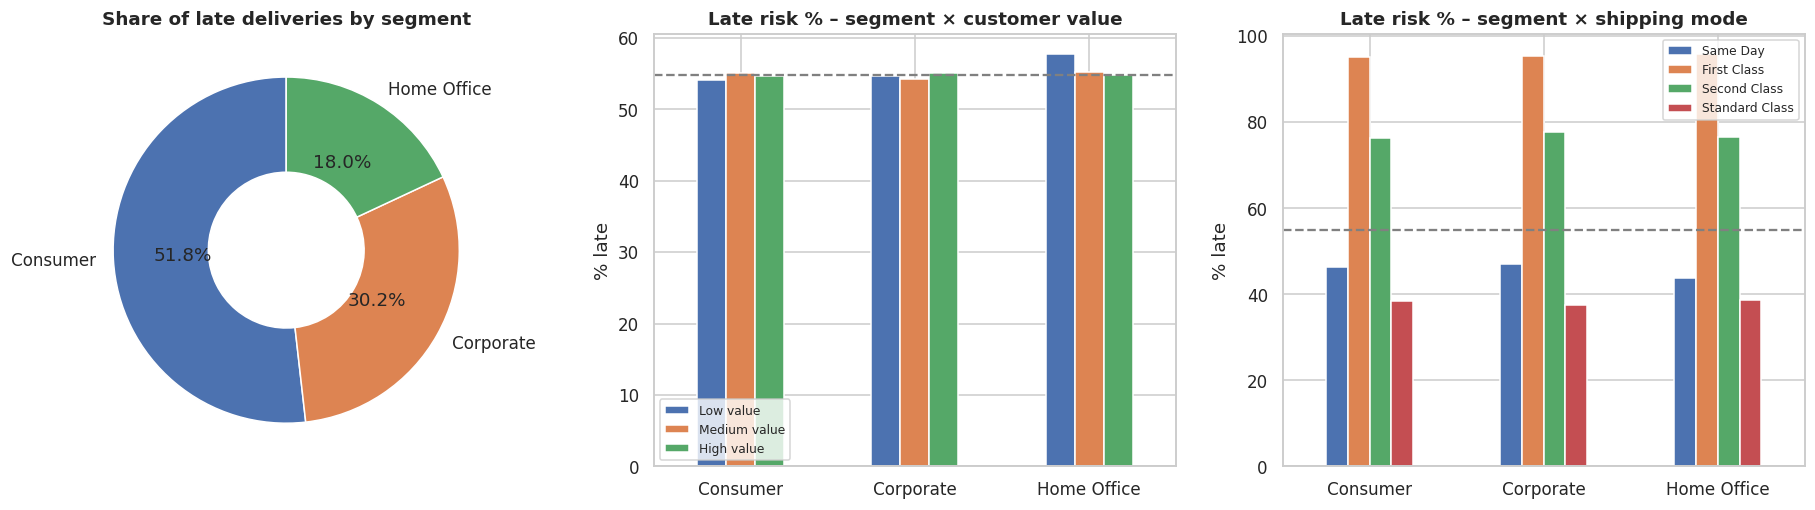

In [ ]:
# 7. OBJECTIVE 4 – Customer segment behaviour
o4 = orders.groupby('segment').agg(orders=('late', 'size'), late_orders=('late', 'sum'), late_pct=('late', 'mean'))
o4['share_of_late_%'] = (o4.late_orders / o4.late_orders.sum() * 100).round(1); o4['late_pct'] *= 100
print(o4.round(1)); chi('segment'); chi('value_tier')

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].pie(o4.late_orders, labels=o4.index, autopct='%1.1f%%', startangle=90, wedgeprops=dict(width=.55))
ax[0].set_title('Share of late deliveries by segment')
tab = orders.pivot_table(index='segment', columns='value_tier', values='late', aggfunc='mean').mul(100)
tab.plot.bar(ax=ax[1], rot=0); ax[1].set_title('Late risk % – segment × customer value'); ax[1].set_ylabel('% late'); ax[1].set_xlabel('')
tab2 = orders.pivot_table(index='segment', columns='ship_mode', values='late', aggfunc='mean').mul(100)[mode_order]
tab2.plot.bar(ax=ax[2], rot=0); ax[2].set_title('Late risk % – segment × shipping mode'); ax[2].set_ylabel('% late'); ax[2].set_xlabel('')
for a in ax[1:]:
    a.axhline(orders.late.mean() * 100, ls='--', c='grey'); a.legend(fontsize=8)
save('04_customer_segments')

## Objective 5 – Temporal Trends in Delivery Delays
**Question:** is late delivery risk cyclical, improving or worsening over time?

**Visuals:** monthly line chart (with 3-month moving average), quarterly bars, seasonality by calendar month and by weekday, and a KPI card.

**Notes**
- The **linear trend** (percentage points per month) summarises the long-term direction; values close to 0 mean no real trend.
- The seasonality charts and chi-square test show whether any month or weekday is systematically worse.
- Check the first and last months for incomplete data before interpreting edge points.

            orders  late_pct  roll3
order_date                         
2017-08-01    1768      55.5   54.8
2017-09-01    1723      54.6   54.7
2017-10-01    2101      54.1   54.6
2017-11-01    2055      55.1   54.8
2017-12-01    2124      55.2   55.5
2018-01-01    2123      56.3    NaN
Linear trend: +0.004 percentage points / month


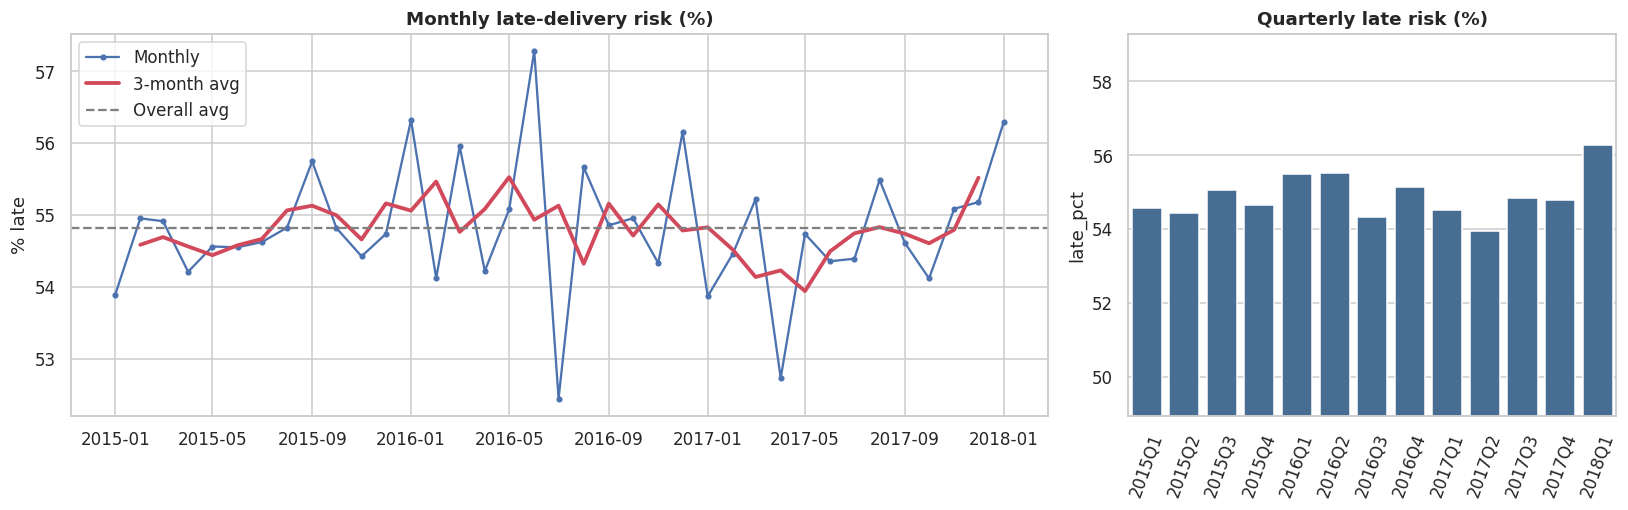

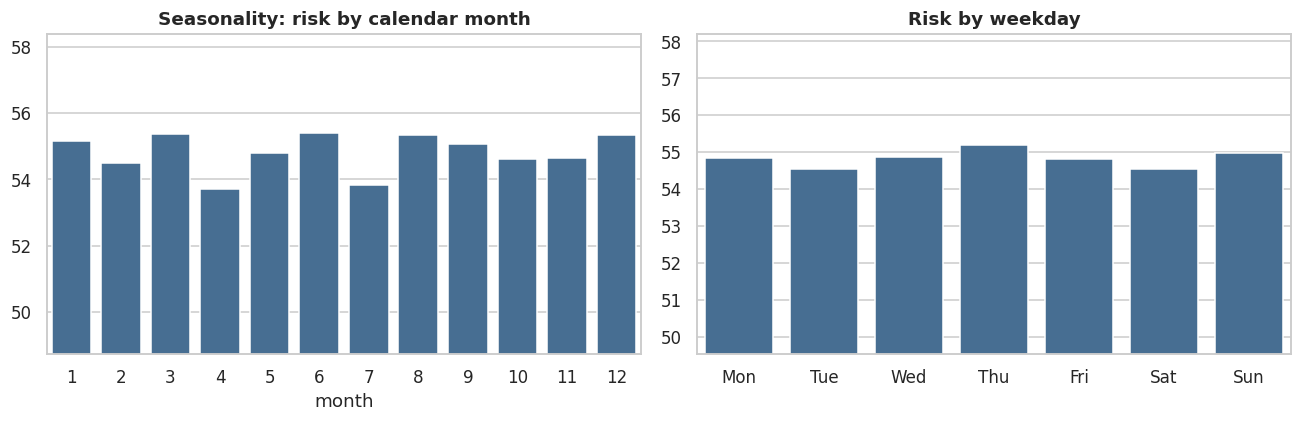

Chi-square test (month): p = 0.716, Cramér's V = 0.011


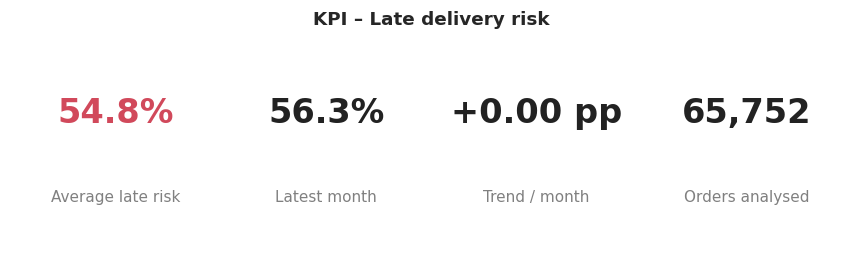

In [ ]:
# 8. OBJECTIVE 5 – Temporal trends
monthly = (orders.set_index('order_date').resample('MS').agg(orders=('late', 'size'), late_pct=('late', 'mean')))
monthly['late_pct'] *= 100; monthly['roll3'] = monthly.late_pct.rolling(3, center=True).mean()
quarterly = orders.groupby('quarter').agg(orders=('late', 'size'), late_pct=('late', 'mean')); quarterly['late_pct'] *= 100
slope = np.polyfit(np.arange(len(monthly)), monthly.late_pct, 1)[0]
print(monthly.round(1).tail(6)); print(f'Linear trend: {slope:+.3f} percentage points / month')

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios': [2, 1]})
ax[0].plot(monthly.index, monthly.late_pct, marker='o', ms=3, label='Monthly')
ax[0].plot(monthly.index, monthly.roll3, lw=2.5, c='#D1495B', label='3-month avg')
ax[0].axhline(orders.late.mean() * 100, ls='--', c='grey', label='Overall avg')
ax[0].set_title('Monthly late-delivery risk (%)'); ax[0].set_ylabel('% late'); ax[0].legend()
sns.barplot(x=quarterly.index, y=quarterly.late_pct, ax=ax[1], color='#3B6E9E')
ax[1].set_title('Quarterly late risk (%)'); ax[1].tick_params(axis='x', rotation=70); ax[1].set_xlabel('')
ax[1].set_ylim(quarterly.late_pct.min() - 5, quarterly.late_pct.max() + 3)
save('05_temporal_trend')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
moy = orders.groupby('month').late.mean().mul(100); dow = orders.groupby('dow').late.mean().mul(100)
sns.barplot(x=moy.index, y=moy.values, ax=ax[0], color='#3B6E9E'); ax[0].set_title('Seasonality: risk by calendar month'); ax[0].set_ylim(moy.min() - 5, moy.max() + 3)
sns.barplot(x=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], y=dow.values, ax=ax[1], color='#3B6E9E'); ax[1].set_title('Risk by weekday'); ax[1].set_ylim(dow.min() - 5, dow.max() + 3)
save('05_seasonality'); chi('month')

# KPI card
fig, ax = plt.subplots(figsize=(8, 2.6)); ax.axis('off')
kpis = [(f'{orders.late.mean():.1%}', 'Average late risk'), (f'{monthly.late_pct.iloc[-1]:.1f}%', 'Latest month'),
        (f'{slope:+.2f} pp', 'Trend / month'), (f'{len(orders):,}', 'Orders analysed')]
for i, (v, l) in enumerate(kpis):
    ax.text(.125 + i * .25, .6, v, ha='center', fontsize=22, fontweight='bold', color='#D1495B' if i == 0 else '#222')
    ax.text(.125 + i * .25, .25, l, ha='center', fontsize=10, color='grey')
ax.set_title('KPI – Late delivery risk', fontweight='bold'); save('05_kpi_card')

## Predictive Modelling – will an order be late?
**Goal:** classify each order as late (1) or on time (0) using information available **at order time**.

**Features**
- Categorical: shipping mode, market, region, country, customer segment, payment type, primary category and department
- Numeric: scheduled shipping days, number of items, quantity, order value, discount, unit price, month, weekday, hour

**Leakage control:** `days_real`, `delay_days`, `ship_date`, `Delivery Status` and `Order Status` are **excluded** because they are only known after delivery and would make the model look artificially perfect.

**Method**
- 80/20 stratified train/test split
- Three models compared: Logistic Regression (baseline), Random Forest, Gradient Boosting
- Metrics: accuracy, precision, recall, F1, ROC-AUC; best model chosen by ROC-AUC and validated with 5-fold cross-validation
- Outputs: ROC curves, confusion matrix, and permutation feature importance (how much AUC drops when a feature is shuffled)

**How to read it:** ROC-AUC of 0.5 = guessing, 1.0 = perfect. Precision = of orders flagged late, how many truly were; recall = of truly late orders, how many were caught.

                     Accuracy  Precision  Recall      F1  ROC-AUC
Model                                                            
Gradient Boosting      0.7158     0.8566  0.5784  0.6905   0.7689
Random Forest          0.7153     0.8559  0.5781  0.6901   0.7638
Logistic Regression    0.7021     0.8431  0.5610  0.6737   0.7431

Best model: Gradient Boosting
              precision    recall  f1-score   support

     On time       0.63      0.88      0.74      5941
        Late       0.86      0.58      0.69      7210

    accuracy                           0.72     13151
   macro avg       0.74      0.73      0.71     13151
weighted avg       0.76      0.72      0.71     13151

5-fold CV ROC-AUC: 0.7692 ± 0.0035


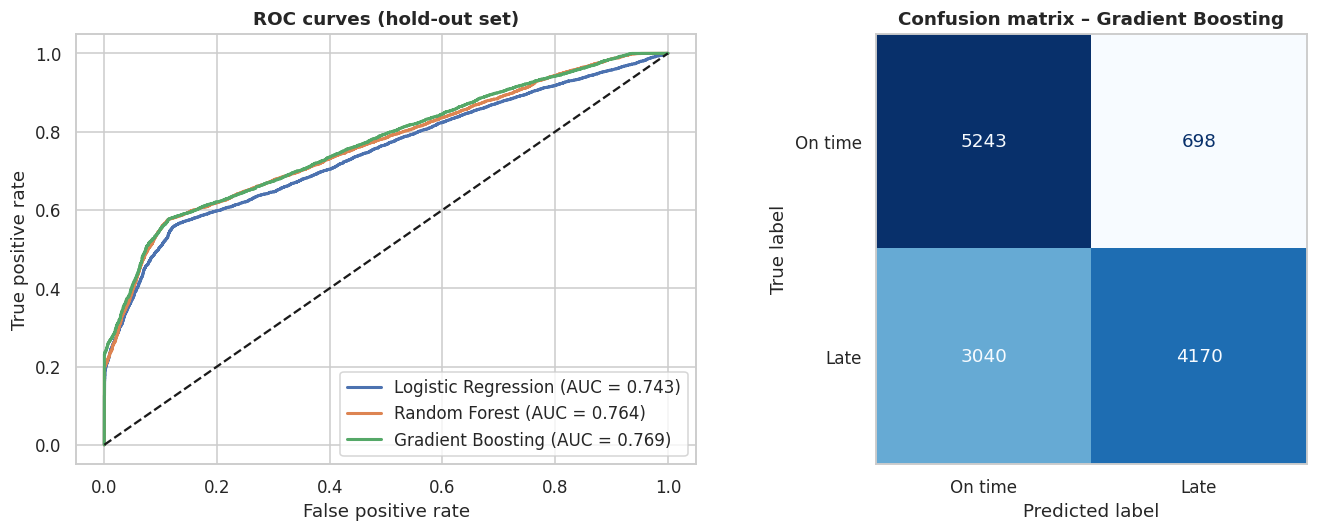

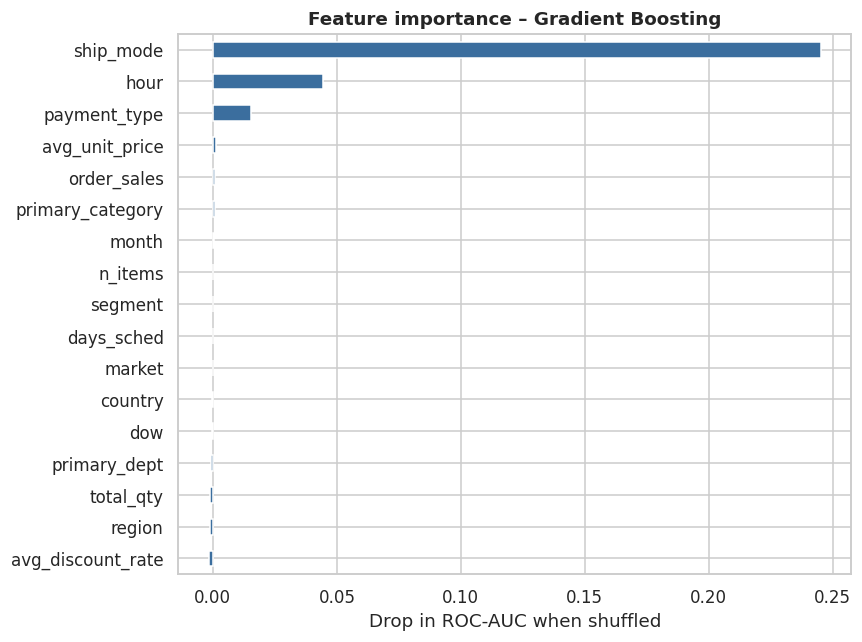

In [ ]:
# 9. PREDICTIVE MODEL
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.inspection import permutation_importance

# Only information known at order time. EXCLUDED (leakage): days_real, delay_days, ship_date, Delivery Status, Order Status.
CAT = ['ship_mode', 'market', 'region', 'country', 'segment', 'payment_type', 'primary_category', 'primary_dept']
NUM = ['days_sched', 'n_items', 'total_qty', 'order_sales', 'avg_discount_rate', 'avg_unit_price', 'month', 'dow', 'hour']
X, y = orders[CAT + NUM], orders['late']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

def make(model, scale=False):
    pre = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=20, sparse_output=False), CAT),
                             ('num', StandardScaler() if scale else 'passthrough', NUM)])
    return Pipeline([('pre', pre), ('model', model)])

models = {'Logistic Regression': make(LogisticRegression(max_iter=1000), scale=True),
          'Random Forest': make(RandomForestClassifier(n_estimators=250, min_samples_leaf=5, n_jobs=-1, random_state=42)),
          'Gradient Boosting': make(HistGradientBoostingClassifier(max_depth=6, learning_rate=0.08, max_iter=300, random_state=42))}
rows, probs = [], {}
for name, m in models.items():
    m.fit(X_tr, y_tr); p = m.predict_proba(X_te)[:, 1]; pred = (p >= .5).astype(int); probs[name] = p
    rows.append({'Model': name, 'Accuracy': accuracy_score(y_te, pred), 'Precision': precision_score(y_te, pred),
                 'Recall': recall_score(y_te, pred), 'F1': f1_score(y_te, pred), 'ROC-AUC': roc_auc_score(y_te, p)})
results = pd.DataFrame(rows).set_index('Model').round(4).sort_values('ROC-AUC', ascending=False)
print(results); results.to_csv(OUT_DIR + 'model_comparison.csv')
best_name = results.index[0]; best = models[best_name]; print('\nBest model:', best_name)
print(classification_report(y_te, (probs[best_name] >= .5).astype(int), target_names=['On time', 'Late']))
cv = cross_val_score(make(best.named_steps['model']), X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring='roc_auc', n_jobs=-1)
print(f'5-fold CV ROC-AUC: {cv.mean():.4f} ± {cv.std():.4f}')

# ROC curves + confusion matrix
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_te, p); ax[0].plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc_score(y_te, p):.3f})')
ax[0].plot([0, 1], [0, 1], 'k--'); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate')
ax[0].set_title('ROC curves (hold-out set)'); ax[0].legend(loc='lower right')
ConfusionMatrixDisplay(confusion_matrix(y_te, (probs[best_name] >= .5).astype(int)), display_labels=['On time', 'Late']).plot(ax=ax[1], cmap='Blues', colorbar=False)
ax[1].set_title(f'Confusion matrix – {best_name}'); ax[1].grid(False)
save('06_roc_confusion')

# Feature importance (permutation, grouped by original feature)
sample = X_te.sample(min(10000, len(X_te)), random_state=1)
pi = permutation_importance(best, sample, y_te.loc[sample.index], scoring='roc_auc', n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
plt.figure(figsize=(8, 6)); imp.plot.barh(color='#3B6E9E'); plt.xlabel('Drop in ROC-AUC when shuffled')
plt.title(f'Feature importance – {best_name}'); save('06_feature_importance')
imp.sort_values(ascending=False).rename('importance').to_csv(OUT_DIR + 'feature_importance.csv')

## Step 10 – Export predictions
Refits the best model on the training set and scores **every** order. Saves `model_predictions.csv` with the actual flag, predicted probability, predicted flag (threshold 0.5), a Low / Medium / High risk band, and a `split` column (train / test).

Use only the `test` rows when reporting model accuracy – training rows are for context and dashboards.

In [ ]:
# 10. Export predictions (for Power BI / report)
best.fit(X_tr, y_tr)
pred_df = orders[['Order Id', 'order_date', 'ship_mode', 'region', 'country', 'segment', 'primary_dept', 'late']].copy()
pred_df['predicted_prob'] = best.predict_proba(X)[:, 1].round(4)
pred_df['predicted_flag'] = (pred_df.predicted_prob >= .5).astype(int)
pred_df['risk_band'] = pd.cut(pred_df.predicted_prob, [-.01, .33, .66, 1], labels=['Low', 'Medium', 'High'])
pred_df['split'] = np.where(pred_df.index.isin(X_te.index), 'test', 'train')
pred_df.rename(columns={'late': 'actual_flag'}).to_csv(OUT_DIR + 'model_predictions.csv', index=False)
print(pred_df.groupby('split').predicted_flag.value_counts().unstack())
print('Saved to', OUT_DIR); print(sorted(os.listdir(OUT_DIR)))

predicted_flag      0      1
split                       
test             8283   4868
train           32668  19933
Saved to /content/outputs/
['00_overview.png', '01_shipping_mode.png', '02_country_map.html', '02_region_bar.png', '03_category_treemap.html', '03_department_stacked.png', '04_customer_segments.png', '05_kpi_card.png', '05_seasonality.png', '05_temporal_trend.png', '06_feature_importance.png', '06_roc_confusion.png', 'feature_importance.csv', 'master_orders.csv', 'model_comparison.csv', 'model_predictions.csv', 'powerbi']


## Step 11 – Power BI export
Writes cleaned tables to `outputs/powerbi/` as a star schema:
- **Facts:** `fact_orders`, `fact_order_items`, `fact_predictions`
- **Dimensions:** `dim_date`, `dim_geography`, `dim_customer`, `dim_product`, `dim_shipping`, `dim_payment`
- **Model tables:** `model_metrics`, `model_roc_points`, `model_feature_importance`

**Relationships to create in Power BI:** `fact_orders` → `Shipment_Id`, `Location_Id`, `Order Customer Id`, `Payment_Type_ID` to the matching dimensions; `fact_orders[order_day]` → `dim_date[Date]`; `fact_order_items` → `fact_orders` (Order Id) and `dim_product`; `fact_predictions` → `fact_orders` (Order Id).

Build late % as a DAX measure: `DIVIDE(SUM(fact_orders[late]), COUNTROWS(fact_orders))`.

In [ ]:
# 11. Power BI export (star schema: one CSV per table + model outputs)
PBI = OUT_DIR + 'powerbi/'; os.makedirs(PBI, exist_ok=True)
def out(df, name): df.to_csv(PBI + name + '.csv', index=False)

fact_orders = orders[['Order Id', 'Order Customer Id', 'Shipment_Id', 'Location_Id', 'Payment_Type_ID', 'order_date', 'ship_date',
                      'Order Status', 'Delivery Status', 'late', 'days_real', 'days_sched', 'delay_days', 'n_items', 'total_qty',
                      'order_sales', 'avg_discount_rate', 'primary_category', 'primary_dept']].copy()
fact_orders['order_day'] = fact_orders.order_date.dt.normalize()                      # join key to dim_date
d = pd.date_range(orders.order_date.min().normalize(), orders.order_date.max().normalize())
dim_date = pd.DataFrame({'Date': d, 'Year': d.year, 'Quarter': 'Q' + d.quarter.astype(str), 'Month No': d.month,
                         'Month': d.strftime('%b'), 'Month Start': d.to_period('M').to_timestamp(), 'Weekday': d.strftime('%a')})
dim_geo = geo.copy(); dim_geo['iso3'] = dim_geo['Order Country'].map(ISO)
dim_cust = cust[['Customer Id', 'Customer Segment', 'Customer Country']].merge(
    tier.rename('Value Tier').reset_index().rename(columns={'Order Customer Id': 'Customer Id'}), on='Customer Id', how='left')
dim_product = (prod[['Product Card Id', 'Product Name', 'Product Category Id', 'Product Price']]
               .merge(cat, left_on='Product Category Id', right_on='Category Id', how='left')
               .merge(dept, on='Department Id', how='left')
               .drop(columns=['Category Id', 'Product Category Id']))
fact_items = items[['Order Item Id', 'Order Id', 'Product Card Id', 'Order Item Quantity', 'Sales', 'Order Item Total',
                    'Order Item Discount Rate']]
fact_pred = pred_df[['Order Id', 'predicted_prob', 'predicted_flag', 'risk_band', 'split']]
roc_pts = pd.concat([pd.DataFrame(dict(zip(['fpr', 'tpr'], roc_curve(y_te, p)[:2])), ).assign(model=n) for n, p in probs.items()])

for name, df in {'fact_orders': fact_orders, 'fact_order_items': fact_items, 'fact_predictions': fact_pred,
                 'dim_date': dim_date, 'dim_geography': dim_geo, 'dim_customer': dim_cust, 'dim_product': dim_product,
                 'dim_shipping': ship, 'dim_payment': pay, 'model_metrics': results.reset_index(),
                 'model_roc_points': roc_pts, 'model_feature_importance': imp.sort_values(ascending=False).rename('importance').reset_index().rename(columns={'index': 'feature'})}.items():
    out(df, name)
print('Power BI tables:', sorted(os.listdir(PBI)))

Power BI tables: ['dim_customer.csv', 'dim_date.csv', 'dim_geography.csv', 'dim_payment.csv', 'dim_product.csv', 'dim_shipping.csv', 'fact_order_items.csv', 'fact_orders.csv', 'fact_predictions.csv', 'model_feature_importance.csv', 'model_metrics.csv', 'model_roc_points.csv']


## Step 12 – Model inference app (Streamlit)
The model is deployed as a web app: **[Late Delivery Risk – live app](https://late-delivery-risk-prediction-dataco.streamlit.app/)**

**What it does**
- **Risk calculator:** enter an order (shipping mode, department, day, hour, payment, basket), click **Predict**, get the late-delivery probability, a Low / Medium / High band (the same bands as Step 10: cut-offs at about one-third and two-thirds) and a suggested action.
- **Scored orders:** browse all 65,752 orders scored by the model, filtered by year, mode and band.
- **Model:** headline metrics and feature importance.

**How it runs**
- Streamlit apps run from `.py` files with `streamlit run app.py`, **not inside a notebook cell**. The cells below write the app's code to `outputs/streamlit_app/` for reference and reproducibility; the live app runs from the same files in the GitHub repository.
- The app uses a lightweight copy of the Gradient Boosting model, exported to `model.json` and scored in pure Python (`risk_model.py`), so the app does not need scikit-learn. It is trained on order-time fields only and reaches a test ROC-AUC of 0.770 (the notebook model in Step 9: 0.769).

**Files in the repository:** `app.py`, `risk_model.py`, `requirements.txt`, `model.json`, `late_risk_scored_orders.csv`, `logo.png`, plus the theme file `.streamlit/config.toml`.

**To run it on your own PC:** put the six files in one folder, then run `pip install -r requirements.txt` and `streamlit run app.py`.

In [1]:
# 12a. Folder for the app files
import os
os.makedirs('/content/outputs/streamlit_app', exist_ok=True)

In [2]:
%%writefile /content/outputs/streamlit_app/requirements.txt
streamlit>=1.36
pandas>=2.0
altair>=5.0


Writing /content/outputs/streamlit_app/requirements.txt


In [3]:
%%writefile /content/outputs/streamlit_app/risk_model.py
"""Late-delivery risk model: pure-Python scorer for the exported Gradient Boosting trees (no scikit-learn needed)."""
import json
import math
from pathlib import Path

MODEL = json.loads((Path(__file__).parent / "model.json").read_text())
MODES = {"First Class": 1, "Second Class": 2, "Same Day": 0, "Standard Class": 4}
PROMISE_DAYS = {1: 1, 2: 2, 0: 0, 4: 4}
BANDS = [(2 / 3, "High"), (1 / 3, "Medium"), (0.0, "Low")]  # same cut-offs as the notebook
BAND_COLOURS = {"High": "#c93f52", "Medium": "#c98a0b", "Low": "#2f8a5f"}
DEPTS = MODEL["depts"]
DEFAULTS = MODEL["defaults"]


def predict(order: dict) -> float:
    """order keys: days_sched, hour, dow, month, Payment_Type_ID, n_items, total_qty, order_sales, avg_discount_rate, dept_code"""
    x = [order[f] for f in MODEL["features"]]
    raw = MODEL["init"]
    for left, right, feat, thr, val in MODEL["trees"]:
        n = 0
        while left[n] != -1:
            n = left[n] if x[feat[n]] <= thr[n] else right[n]
        raw += MODEL["lr"] * val[n]
    return 1.0 / (1.0 + math.exp(-raw))


def band(p: float) -> str:
    for cut, name in BANDS:
        if p >= cut:
            return name
    return "Low"


def action(b: str) -> str:
    return {"High": "Likely to miss its promised date. Quote a realistic date, warn the customer, or upgrade the carrier.",
            "Medium": "Could go either way. Monitor it and consider a proactive delay notice.",
            "Low": "Likely to arrive on time. No action needed at checkout."}[b]


Writing /content/outputs/streamlit_app/risk_model.py


In [4]:
%%writefile /content/outputs/streamlit_app/app.py
"""Late Delivery Risk – Streamlit app for the DataCo supply chain capstone."""
import base64
from pathlib import Path

import altair as alt
import pandas as pd
import streamlit as st

from risk_model import BAND_COLOURS, DEFAULTS, DEPTS, MODEL, MODES, PROMISE_DAYS, action, band, predict

HERE = Path(__file__).parent  # files are found next to app.py, wherever the repository puts it
st.set_page_config(page_title="Late Delivery Risk", page_icon=str(HERE / "logo.png"), layout="wide")

NAVY, NAVY2, ORANGE, MUTED, LINE = "#1b3a6b", "#2c4f8a", "#e8792b", "#5b6676", "#e3e8f0"
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
PAY_NAMES = {1: "Debit", 2: "Transfer", 3: "Cash", 4: "Payment"}  # DataCo payment types (matched via order status)
MODE_NOTE = {"First Class": "promises 1 day", "Second Class": "promises 2 days", "Same Day": "same-day dispatch",
             "Standard Class": "promises 4 days"}
LOGO = base64.b64encode((HERE / "logo.png").read_bytes()).decode()


# ---------------- helpers ----------------
def stretch(fn, *args, **kwargs):
    """Full-width element on any Streamlit version (newer: width='stretch'; older: use_container_width)."""
    try:
        return fn(*args, width="stretch", **kwargs)
    except TypeError:
        return fn(*args, use_container_width=True, **kwargs)


def styled(chart, height=260):
    return (chart.properties(height=height)
            .configure(font="Segoe UI, Inter, system-ui, sans-serif")
            .configure_view(strokeWidth=0)
            .configure_axis(labelColor=MUTED, titleColor=MUTED, gridColor="#edf0f5", domainColor=LINE, tickColor=LINE,
                            labelFontSize=12, titleFontSize=12, titleFontWeight="normal")
            .configure_legend(labelColor=MUTED, titleColor=MUTED, orient="top", labelFontSize=12))


def section(title, sub=""):
    st.markdown(f"<div class='sec'><b>{title}</b>{f'<span>{sub}</span>' if sub else ''}</div>", unsafe_allow_html=True)


def pct(x):
    return f"{x:.0%}"


st.markdown(f"""<style>
#MainMenu, footer, [data-testid="stDecoration"] {{visibility:hidden; height:0}}
[data-testid="stHeader"] {{background:transparent}}
.block-container {{padding-top:1.4rem; padding-bottom:2rem; max-width:1320px}}
.hero {{background:linear-gradient(110deg,{NAVY} 0%,{NAVY2} 70%,#3a64a6 100%); border-radius:18px; padding:22px 28px;
        display:flex; align-items:center; gap:22px; color:#fff; box-shadow:0 10px 30px rgba(27,58,107,.18); margin-bottom:.6rem}}
.hero img {{width:92px; height:auto; background:#fff; border-radius:14px; padding:6px}}
.hero h1 {{color:#fff; font-size:2.05rem; margin:0; padding:0; line-height:1.15}}
.hero p {{margin:.3rem 0 .7rem; color:#d6e1f2; font-size:1rem}}
.chip {{display:inline-block; background:rgba(255,255,255,.14); border:1px solid rgba(255,255,255,.25); color:#fff;
        border-radius:999px; padding:3px 12px; font-size:.82rem; margin:0 6px 4px 0}}
.chip.o {{background:{ORANGE}; border-color:{ORANGE}; font-weight:700}}
.sec {{display:flex; align-items:baseline; gap:10px; margin:.2rem 0 .5rem}}
.sec b {{font-size:1.05rem; color:{NAVY}}} .sec span {{color:{MUTED}; font-size:.85rem}}
.lbl {{font-size:.72rem; letter-spacing:.09em; text-transform:uppercase; font-weight:800; color:#8a94a6; margin:.5rem 0 .1rem}}
[data-testid="stForm"], [data-testid="stVerticalBlockBorderWrapper"] {{background:#fff; border:1px solid {LINE} !important;
        border-radius:16px; box-shadow:0 1px 2px rgba(16,24,40,.04),0 6px 18px rgba(16,24,40,.05)}}
[data-testid="stMetric"] {{background:#fff; border:1px solid {LINE}; border-radius:14px; padding:14px 18px;
        box-shadow:0 1px 2px rgba(16,24,40,.04)}}
[data-testid="stMetricLabel"] p {{color:{MUTED}; font-weight:600}}
[data-testid="stMetricValue"] {{color:{NAVY}; font-weight:800}}
.stTabs [data-baseweb="tab-list"] {{gap:6px; border-bottom:1px solid {LINE}}}
.stTabs [data-baseweb="tab"] {{font-weight:700; padding:10px 18px; border-radius:10px 10px 0 0}}
.stTabs [aria-selected="true"] {{color:{NAVY}; background:#fff}}
.res {{display:flex; gap:22px; align-items:center; flex-wrap:wrap}}
.big {{font-size:3.6rem; font-weight:800; line-height:1}}
.pill {{display:inline-block; color:#fff; font-weight:800; letter-spacing:.06em; font-size:.8rem; padding:5px 14px; border-radius:999px}}
.scale {{position:relative; margin:22px 0 6px}}
.scale .bar {{display:flex; height:12px; border-radius:99px; overflow:hidden}}
.scale .bar i {{display:block; height:100%}}
.scale .mk {{position:absolute; top:-9px; width:3px; height:30px; background:#1b2230; border-radius:2px; transform:translateX(-50%)}}
.scale .mk span {{position:absolute; top:-22px; left:50%; transform:translateX(-50%); font-size:.78rem; font-weight:800; white-space:nowrap}}
.scale .ticks {{display:grid; grid-template-columns:repeat(3,1fr); text-align:center; font-size:.75rem; color:{MUTED}; margin-top:6px}}
.act {{border-left:4px solid; border-radius:10px; padding:12px 16px; background:#f7f9fc; margin-top:14px}}
.act b {{display:block; margin-bottom:2px}}
.tip {{background:#fff7ef; border:1px solid #f6d9bd; border-radius:12px; padding:12px 16px; margin-top:12px}}
.empty {{text-align:center; padding:56px 30px; color:{MUTED}}}
.empty h3 {{color:{NAVY}; margin:.4rem 0}}
.steps {{display:flex; gap:12px; justify-content:center; margin-top:18px; flex-wrap:wrap}}
.steps div {{background:#f4f6fa; border-radius:12px; padding:10px 16px; font-size:.9rem}}
.steps b {{color:{ORANGE}; margin-right:6px}}
.cm {{display:grid; grid-template-columns:110px 1fr 1fr; gap:8px; font-size:.85rem; color:{MUTED}}}
.cm .h {{text-align:center; font-weight:700}} .cm .r {{display:flex; align-items:center; font-weight:700}}
.cm .c {{border-radius:12px; text-align:center; padding:16px 6px}} .cm .c b {{display:block; font-size:1.6rem}}
.foot {{color:#8a94a6; font-size:.8rem; text-align:center; margin-top:2rem}}
</style>""", unsafe_allow_html=True)

st.markdown(f"""<div class="hero"><img src="data:image/png;base64,{LOGO}" alt="logo"><div>
<h1>Late Delivery Risk</h1>
<p>Score an order at checkout and see how likely it is to arrive late, using only what is known when it is placed.</p>
<span class="chip o">ROC-AUC 0.77</span><span class="chip">Gradient Boosting</span><span class="chip">65,752 orders · Jan 2015 – Jan 2018</span><span class="chip">DataCo supply chain capstone</span>
</div></div>""", unsafe_allow_html=True)


@st.cache_data
def load_scores() -> pd.DataFrame:
    df = pd.read_csv(HERE / "late_risk_scored_orders.csv", parse_dates=["order_date"])
    df["year"] = df["order_date"].dt.year
    df["payment"] = df["Payment_Type_ID"].map(PAY_NAMES)
    return df


tab_calc, tab_orders, tab_model = st.tabs(["Risk calculator", "Scored orders", "About the model"])

# ---------------- calculator ----------------
with tab_calc:
    left, right = st.columns([5, 7], gap="large")

    with left:
        with st.form("order_form", border=True):
            section("Order at checkout", "fill in, then Predict")
            st.markdown("<div class='lbl'>Shipping</div>", unsafe_allow_html=True)
            mode_name = st.radio("Shipping mode", list(MODES), horizontal=True, key="mode", label_visibility="collapsed")
            st.markdown("<div class='lbl'>When</div>", unsafe_allow_html=True)
            hour = st.slider("Order hour", 0, 23, 14, format="%d:00", key="hour")
            a, b = st.columns(2)
            dow = a.selectbox("Day of week", range(7), index=2, format_func=lambda d: DAYS[d], key="dow")
            month = b.selectbox("Month", range(1, 13), index=5, format_func=lambda m: MONTHS[m - 1], key="month")
            st.markdown("<div class='lbl'>Basket</div>", unsafe_allow_html=True)
            a, b = st.columns(2)
            dept = a.selectbox("Main department", range(len(DEPTS)), index=DEPTS.index("Fitness"), format_func=lambda i: DEPTS[i], key="dept")
            pay_ids = sorted(int(k) for k in MODEL["pay_n"])
            pay = b.selectbox("Payment type", pay_ids, format_func=lambda k: PAY_NAMES.get(k, f"Type {k}"), key="pay")
            n_items = a.number_input("Items in order", 1, 5, int(DEFAULTS["n_items"]), key="items")
            qty = b.number_input("Total quantity", 1, 25, int(DEFAULTS["total_qty"]), key="qty")
            sales = a.number_input("Order value ($)", 5.0, 2500.0, float(round(DEFAULTS["order_sales"])), step=5.0, key="sales")
            disc = b.number_input("Average discount (%)", 0, 25, int(round(DEFAULTS["avg_discount_rate"] * 100)), key="disc")
            submitted = stretch(st.form_submit_button, "Predict late-delivery risk", type="primary")

    if submitted:
        st.session_state["order"] = dict(days_sched=MODES[mode_name], hour=hour, dow=dow, month=month, Payment_Type_ID=pay,
                                         n_items=n_items, total_qty=qty, order_sales=sales, avg_discount_rate=disc / 100, dept_code=dept)
        st.session_state["order_label"] = (f"{mode_name} · {DAYS[dow]} {hour:02d}:00 · {MONTHS[month - 1]} · "
                                           f"{n_items} item(s), ${sales:,.0f} · {DEPTS[dept]} · {PAY_NAMES.get(pay, pay)}")

    with right:
        if "order" not in st.session_state:
            with st.container(border=True):
                st.markdown(f"""<div class="empty"><img src="data:image/png;base64,{LOGO}" width="110" alt="">
<h3>Score an order</h3><div>Enter the order details on the left and click <b>Predict late-delivery risk</b>.</div>
<div class="steps"><div><b>1</b>Choose the shipping mode</div><div><b>2</b>Set time and basket</div><div><b>3</b>Predict and compare</div></div></div>""",
                            unsafe_allow_html=True)
        else:
            order = st.session_state["order"]
            mode, hour_sel = order["days_sched"], order["hour"]
            mode_label = next(n for n, c in MODES.items() if c == mode)
            p = predict(order)
            bnd = band(p)
            col = BAND_COLOURS[bnd]

            with st.container(border=True):
                section("Prediction", st.session_state["order_label"])
                zones = "".join(f"<i style='width:{w}%;background:{c}'></i>" for w, c in
                                [(100 / 3, BAND_COLOURS["Low"]), (100 / 3, BAND_COLOURS["Medium"]), (100 / 3, BAND_COLOURS["High"])])
                st.markdown(f"""<div class="res"><div><div class="big" style="color:{col}">{pct(p)}</div>
<div style="color:{MUTED};font-size:.9rem">chance this order arrives late</div></div>
<div><span class="pill" style="background:{col}">{bnd.upper()} RISK</span>
<div style="color:{MUTED};font-size:.85rem;margin-top:6px">{mode_label} {MODE_NOTE[mode_label]}</div></div></div>
<div class="scale"><div class="bar" style="opacity:.85">{zones}</div><div class="mk" style="left:{min(max(p, .01), .99) * 100:.1f}%"><span>{pct(p)}</span></div>
<div class="ticks"><span>Low · under 33%</span><span>Medium · 33–67%</span><span>High · 67% and above</span></div></div>
<div class="act" style="border-color:{col}"><b>Recommended action</b>{action(bnd)}</div>""", unsafe_allow_html=True)

                alts = {name: predict({**order, "days_sched": code}) for name, code in MODES.items()}
                best_mode = min(alts, key=alts.get)
                hours = {h: predict({**order, "hour": h}) for h in range(24)}
                best_hour = min(hours, key=hours.get)
                tips = []
                if best_mode != mode_label and p - alts[best_mode] >= 0.02:
                    tips.append(f"Switching to <b>{best_mode}</b> lowers the risk to <b>{pct(alts[best_mode])}</b> "
                                f"({(p - alts[best_mode]) * 100:.0f} points lower).")
                if best_hour != hour_sel and p - hours[best_hour] >= 0.02:
                    tips.append(f"Placed at <b>{best_hour:02d}:00</b>, the same order scores <b>{pct(hours[best_hour])}</b>.")
                if not tips:
                    tips.append("This is already close to the lowest risk this order can get by changing mode or order time.")
                st.markdown("<div class='tip'><b>What would lower the risk?</b><br>" + "<br>".join(tips) + "</div>", unsafe_allow_html=True)

            g1, g2 = st.columns(2)
            with g1:
                with st.container(border=True):
                    section("Same order, other modes")
                    dm = pd.DataFrame([{"mode": n, "risk": r, "selected": n == mode_label} for n, r in alts.items()])
                    dm["band"] = dm["risk"].map(band)
                    base = alt.Chart(dm).encode(y=alt.Y("mode:N", sort=list(MODES), title=None, axis=alt.Axis(labelFontWeight="bold")))
                    bars = base.mark_bar(cornerRadiusEnd=5, size=26).encode(
                        x=alt.X("risk:Q", scale=alt.Scale(domain=[0, 1]), axis=alt.Axis(format="%", title=None, tickCount=5)),
                        color=alt.Color("band:N", scale=alt.Scale(domain=list(BAND_COLOURS), range=list(BAND_COLOURS.values())), legend=None),
                        opacity=alt.condition("datum.selected", alt.value(1), alt.value(0.45)),
                        tooltip=[alt.Tooltip("mode:N", title="Mode"), alt.Tooltip("risk:Q", format=".0%", title="Risk")])
                    text = base.mark_text(align="left", dx=6, fontWeight="bold").encode(
                        x="risk:Q", text=alt.Text("risk:Q", format=".0%"), color=alt.value("#1b2230"))
                    stretch(st.altair_chart, styled(bars + text, 230))
            with g2:
                with st.container(border=True):
                    section("Same order, other times of day")
                    dh = pd.DataFrame([{"hour": h, "risk": r} for h, r in hours.items()])
                    x = alt.X("hour:Q", scale=alt.Scale(domain=[0, 23]), title="Order hour", axis=alt.Axis(tickCount=12))
                    area = alt.Chart(dh).mark_area(line={"color": ORANGE, "strokeWidth": 2.5}, color=ORANGE, opacity=0.12).encode(
                        x=x, y=alt.Y("risk:Q", scale=alt.Scale(domain=[0, 1]), axis=alt.Axis(format="%", title=None, tickCount=5)),
                        tooltip=[alt.Tooltip("hour:Q", title="Hour"), alt.Tooltip("risk:Q", format=".0%", title="Risk")])
                    rules = alt.Chart(pd.DataFrame({"y": [1 / 3, 2 / 3]})).mark_rule(strokeDash=[4, 4], color="#b8c1d1").encode(y=alt.Y("y:Q", title=None))
                    dot = alt.Chart(dh[dh.hour == hour_sel]).mark_point(filled=True, size=110, color=NAVY, opacity=1).encode(x="hour:Q", y="risk:Q")
                    stretch(st.altair_chart, styled(rules + area + dot, 230))

# ---------------- scored orders ----------------
with tab_orders:
    df = load_scores()
    with st.container(border=True):
        section("Filter the scored orders", "every order scored by the model")
        f1, f2, f3, f4 = st.columns(4)
        years = f1.multiselect("Year", sorted(df.year.unique()), default=sorted(df.year.unique()))
        modes = f2.multiselect("Shipping mode", list(MODES), default=list(MODES))
        bands = f3.multiselect("Risk band", ["High", "Medium", "Low"], default=["High", "Medium", "Low"])
        depts = f4.multiselect("Department", sorted(df.primary_dept.dropna().unique()), default=[], placeholder="All departments")
    sel = df[df.year.isin(years) & df.ship_mode.isin(modes) & df.risk_band.isin(bands)]
    if depts:
        sel = sel[sel.primary_dept.isin(depts)]

    k1, k2, k3, k4 = st.columns(4)
    k1.metric("Orders", f"{len(sel):,}")
    k2.metric("Actually late", f"{sel.actual_late.mean():.1%}" if len(sel) else "–")
    k3.metric("Average predicted risk", f"{sel.late_risk.mean():.1%}" if len(sel) else "–")
    k4.metric("High-risk orders", f"{(sel.risk_band == 'High').sum():,}")

    if len(sel):
        s1, s2 = st.columns(2)
        with s1:
            with st.container(border=True):
                section("Orders by risk band", "label = share actually late")
                bc = (sel.groupby("risk_band").agg(orders=("Order Id", "size"), late=("actual_late", "mean"))
                      .reindex(["High", "Medium", "Low"]).dropna().reset_index())
                base = alt.Chart(bc).encode(y=alt.Y("risk_band:N", sort=["High", "Medium", "Low"], title=None, axis=alt.Axis(labelFontWeight="bold")))
                bars = base.mark_bar(cornerRadiusEnd=5, size=30).encode(
                    x=alt.X("orders:Q", title="Orders"),
                    color=alt.Color("risk_band:N", scale=alt.Scale(domain=list(BAND_COLOURS), range=list(BAND_COLOURS.values())), legend=None),
                    tooltip=[alt.Tooltip("risk_band:N", title="Band"), alt.Tooltip("orders:Q", format=",", title="Orders"),
                             alt.Tooltip("late:Q", format=".1%", title="Actually late")])
                text = base.mark_text(align="left", dx=6, color="#1b2230").encode(
                    x="orders:Q", text=alt.Text("late:Q", format=".0%"))
                stretch(st.altair_chart, styled(bars + text, 230))
        with s2:
            with st.container(border=True):
                section("Predicted vs actual late rate", "by shipping mode")
                mm = (sel.groupby("ship_mode").agg(Predicted=("late_risk", "mean"), Actual=("actual_late", "mean"))
                      .reindex([m for m in MODES if m in set(sel.ship_mode)]).reset_index().melt("ship_mode"))
                ch = alt.Chart(mm).mark_bar(cornerRadiusEnd=4).encode(
                    x=alt.X("ship_mode:N", sort=list(MODES), title=None, axis=alt.Axis(labelAngle=0)), xOffset="variable:N",
                    y=alt.Y("value:Q", axis=alt.Axis(format="%", title=None, tickCount=5), scale=alt.Scale(domain=[0, 1])),
                    color=alt.Color("variable:N", scale=alt.Scale(domain=["Predicted", "Actual"], range=[NAVY2, ORANGE]), title=None),
                    tooltip=[alt.Tooltip("ship_mode:N", title="Mode"), alt.Tooltip("variable:N", title=" "), alt.Tooltip("value:Q", format=".1%", title="Rate")])
                stretch(st.altair_chart, styled(ch, 230))

        with st.container(border=True):
            section("Highest-risk orders in this selection", "top 500")
            top = (sel.sort_values("late_risk", ascending=False).head(500)
                   [["Order Id", "order_date", "ship_mode", "primary_dept", "payment", "hour", "n_items", "order_sales", "late_risk", "risk_band", "actual_late"]])
            top["actual_late"] = top["actual_late"].map({1: "Late", 0: "On time"})
            cfg = {"Order Id": st.column_config.NumberColumn("Order", format="%d"),
                   "order_date": st.column_config.DatetimeColumn("Order date", format="D MMM YYYY, HH:mm"),
                   "ship_mode": "Shipping mode", "primary_dept": "Department", "payment": "Payment",
                   "hour": st.column_config.NumberColumn("Hour", format="%d:00"),
                   "n_items": "Items", "order_sales": st.column_config.NumberColumn("Value", format="$%.0f"),
                   "late_risk": st.column_config.ProgressColumn("Late risk", format="%.0f%%", min_value=0, max_value=100),
                   "risk_band": "Band", "actual_late": "Actual"}
            top["late_risk"] = (top["late_risk"] * 100).round(1)
            stretch(st.dataframe, top, hide_index=True, column_config=cfg, height=380)
            st.download_button("Download this selection (CSV)", sel.drop(columns=["year", "payment"]).to_csv(index=False).encode(),
                               "late_risk_selection.csv", "text/csv")
    else:
        st.info("No orders match these filters.")

# ---------------- model ----------------
with tab_model:
    a, b, c, d = st.columns(4)
    a.metric("ROC-AUC (hold-out)", "0.770")
    b.metric("Precision", "86%", help="Of the orders flagged late, the share that really were late.")
    c.metric("Recall", "58%", help="Of the orders that were late, the share the model flagged.")
    d.metric("Accuracy", "72%")
    m1, m2 = st.columns([6, 5], gap="large")
    with m1:
        with st.container(border=True):
            section("How the model works")
            st.markdown("""
- **Model:** Gradient Boosting (100 trees, depth 3), 80/20 stratified split, trained on `fact_orders`.
- **Inputs, all known at checkout:** shipping mode, order hour, day of week, month, payment type, items, quantity, order value, discount and department.
- **No leakage:** actual shipping days and delivery status are left out because they are only known after delivery.
- **Biggest driver:** shipping mode. Order hour comes second, consistent with a dispatch cut-off.
- **Risk bands** (same as the notebook): Low below 33%, Medium 33–67%, High 67% and above.
""")
            cal = pd.DataFrame({"band": ["Low", "Medium", "High"], "late": [0.22, 0.39, 0.86]})
            base = alt.Chart(cal).encode(x=alt.X("band:N", sort=["Low", "Medium", "High"], title=None, axis=alt.Axis(labelAngle=0, labelFontWeight="bold")))
            bars = base.mark_bar(cornerRadiusEnd=5, size=56).encode(
                y=alt.Y("late:Q", scale=alt.Scale(domain=[0, 1]), axis=alt.Axis(format="%", title="Actually late", tickCount=5)),
                color=alt.Color("band:N", scale=alt.Scale(domain=list(BAND_COLOURS), range=list(BAND_COLOURS.values())), legend=None))
            text = base.mark_text(dy=-10, fontWeight="bold", color="#1b2230").encode(y="late:Q", text=alt.Text("late:Q", format=".0%"))
            st.markdown("<div class='lbl'>Bands are well separated: share of orders actually late, out-of-fold</div>", unsafe_allow_html=True)
            stretch(st.altair_chart, styled(bars + text, 210))
    with m2:
        with st.container(border=True):
            section("Confusion matrix", "13,151 test orders · 50% cut-off")
            st.markdown("""<div class="cm"><div></div><div class="h">Predicted late</div><div class="h">Predicted on time</div>
<div class="r">Actually late</div><div class="c" style="background:#e3f2ea"><b style="color:#2f8a5f">4,157</b>caught</div>
<div class="c" style="background:#fbe6e9"><b style="color:#c93f52">3,053</b>missed</div>
<div class="r">Actually on time</div><div class="c" style="background:#fdeedd"><b style="color:#c9700b">678</b>false alarms</div>
<div class="c" style="background:#eef1f6"><b style="color:#1b3a6b">5,263</b>correct on time</div></div>""", unsafe_allow_html=True)
            st.caption("When the model flags an order it is right 86% of the time, and it catches 58% of late orders. "
                       "Lowering the cut-off catches more late orders at the cost of more false alarms.")

st.markdown("<div class='foot'>DataCo supply chain capstone · Late Delivery Risk Prediction · Predictions are estimates for decision support.</div>",
            unsafe_allow_html=True)


Writing /content/outputs/streamlit_app/app.py


In [5]:
# Theme (navy/orange). In the repository this file lives at .streamlit/config.toml
import os
os.makedirs('/content/outputs/streamlit_app/.streamlit', exist_ok=True)
open('/content/outputs/streamlit_app/.streamlit/config.toml', 'w').write('''[theme]
base = "light"
primaryColor = "#1b3a6b"
backgroundColor = "#f4f6fa"
secondaryBackgroundColor = "#eef2f7"
textColor = "#1b2230"
font = "sans serif"

[client]
toolbarMode = "minimal"
''')

189

`model.json`, `late_risk_scored_orders.csv` and `logo.png` are data files, so they are not written here; take them from the GitHub repository.

In [6]:
# 12b. Preview the live app inside the notebook
from IPython.display import IFrame
IFrame('https://late-delivery-risk-prediction-dataco.streamlit.app/?embed=true', width='100%', height=800)

## Step 13 – Download outputs
Colab storage is wiped when the session ends. This zips everything in `/content/outputs` (charts, model results, cleaned data, Power BI tables) and downloads it. Upload the CSVs you need to the GitHub repo afterwards.

In [ ]:
# 13. Download all outputs (Colab storage is temporary)
from google.colab import files
shutil.make_archive('/content/late_risk_outputs', 'zip', OUT_DIR)
files.download('/content/late_risk_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>